**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "net_v4_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v4"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False,                 
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                       # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,

    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                      # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [3]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all3',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm3",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [4]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-03 10:04:55,851 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...


2026-11-03 10:05:00,857 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:05,867 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:10,879 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:15,890 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:20,898 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:25,907 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10:05:30,915 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run cb788f1aec704bde995a68ee86fa0ff5 to finish...
2026-11-03 10

Run anomaly detection ocsvm: cb788f1aec704bde995a68ee86fa0ff5


In [5]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}         
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})


print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: net_v4_0per | moco: net_v4 | punti: encoder, pre_proj, proj_raw, post_proj 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 2048 | shrinkage: 0.013700232083290579
nu: 0.05 | gamma: scale | dim: 2048 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 21.7295 ± 15.1700
score anomale: 5.9731 ± 13.4132
AUROC: 0.778


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-8.378524,403.0,81.0,1999.0,2321.0,0.033722,0.832223,0.167777,0.832645,0.279279
FA 10%,-1.879050,753.0,188.0,1649.0,2214.0,0.078268,0.686511,0.313489,0.800213,0.450494
FA 15%,3.141485,1092.0,329.0,1310.0,2073.0,0.136969,0.545379,0.454621,0.768473,0.571279
FA 20%,7.263181,1331.0,446.0,1071.0,1956.0,0.185679,0.445878,0.554122,0.749015,0.636994
FA 25%,11.055099,1542.0,582.0,860.0,1820.0,0.242298,0.358035,0.641965,0.725989,0.681396
FA 30%,13.864052,1681.0,701.0,721.0,1701.0,0.291840,0.300167,0.699833,0.705709,0.702759


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.010508562533294326
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.049
min_flood_area = 0.000
score normali: 14.8347 ± 8.2209
score anomale: 8.8194 ± 7.3673
AUROC: 0.709


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.610088,178.0,93.0,2224.0,2309.0,0.038718,0.925895,0.074105,0.656827,0.133184
FA 10%,1.611498,462.0,206.0,1940.0,2196.0,0.085762,0.807660,0.192340,0.691617,0.300977
FA 15%,4.349079,750.0,325.0,1652.0,2077.0,0.135304,0.687760,0.312240,0.697674,0.431406
FA 20%,6.792352,1019.0,447.0,1383.0,1955.0,0.186095,0.575770,0.424230,0.695089,0.526887
FA 25%,8.761397,1235.0,565.0,1167.0,1837.0,0.235221,0.485845,0.514155,0.686111,0.587815
FA 30%,10.619178,1413.0,691.0,989.0,1711.0,0.287677,0.411740,0.588260,0.671578,0.627164


===== post_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.0033052560425706184
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 17.9499 ± 13.3275
score anomale: 11.8061 ± 13.0281
AUROC: 0.630


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-6.611557,199.0,98.0,2203.0,2304.0,0.040799,0.917152,0.082848,0.670034,0.147462
FA 10%,0.157129,453.0,209.0,1949.0,2193.0,0.087011,0.811407,0.188593,0.684290,0.295692
FA 15%,3.865144,614.0,334.0,1788.0,2068.0,0.139051,0.744380,0.255620,0.647679,0.366567
FA 20%,6.607062,774.0,438.0,1628.0,1964.0,0.182348,0.677769,0.322231,0.638614,0.428334
FA 25%,8.717134,905.0,539.0,1497.0,1863.0,0.224396,0.623231,0.376769,0.626731,0.470619
FA 30%,10.909885,1065.0,664.0,1337.0,1738.0,0.276436,0.556619,0.443381,0.615963,0.515614


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,2048,0.014,0.778
proj_raw,256,0.011,0.709
post_proj,256,0.003,0.630


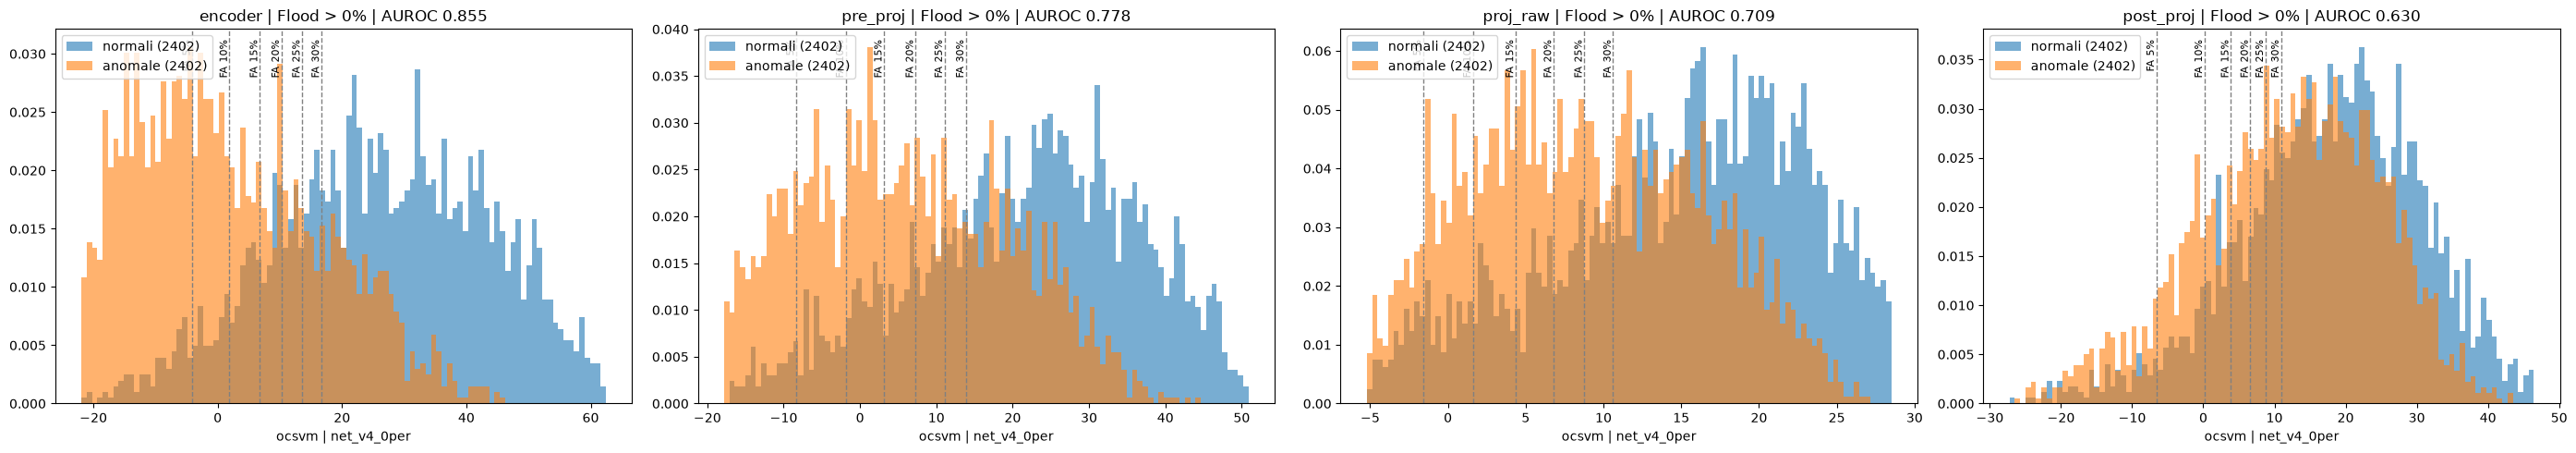

In [6]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

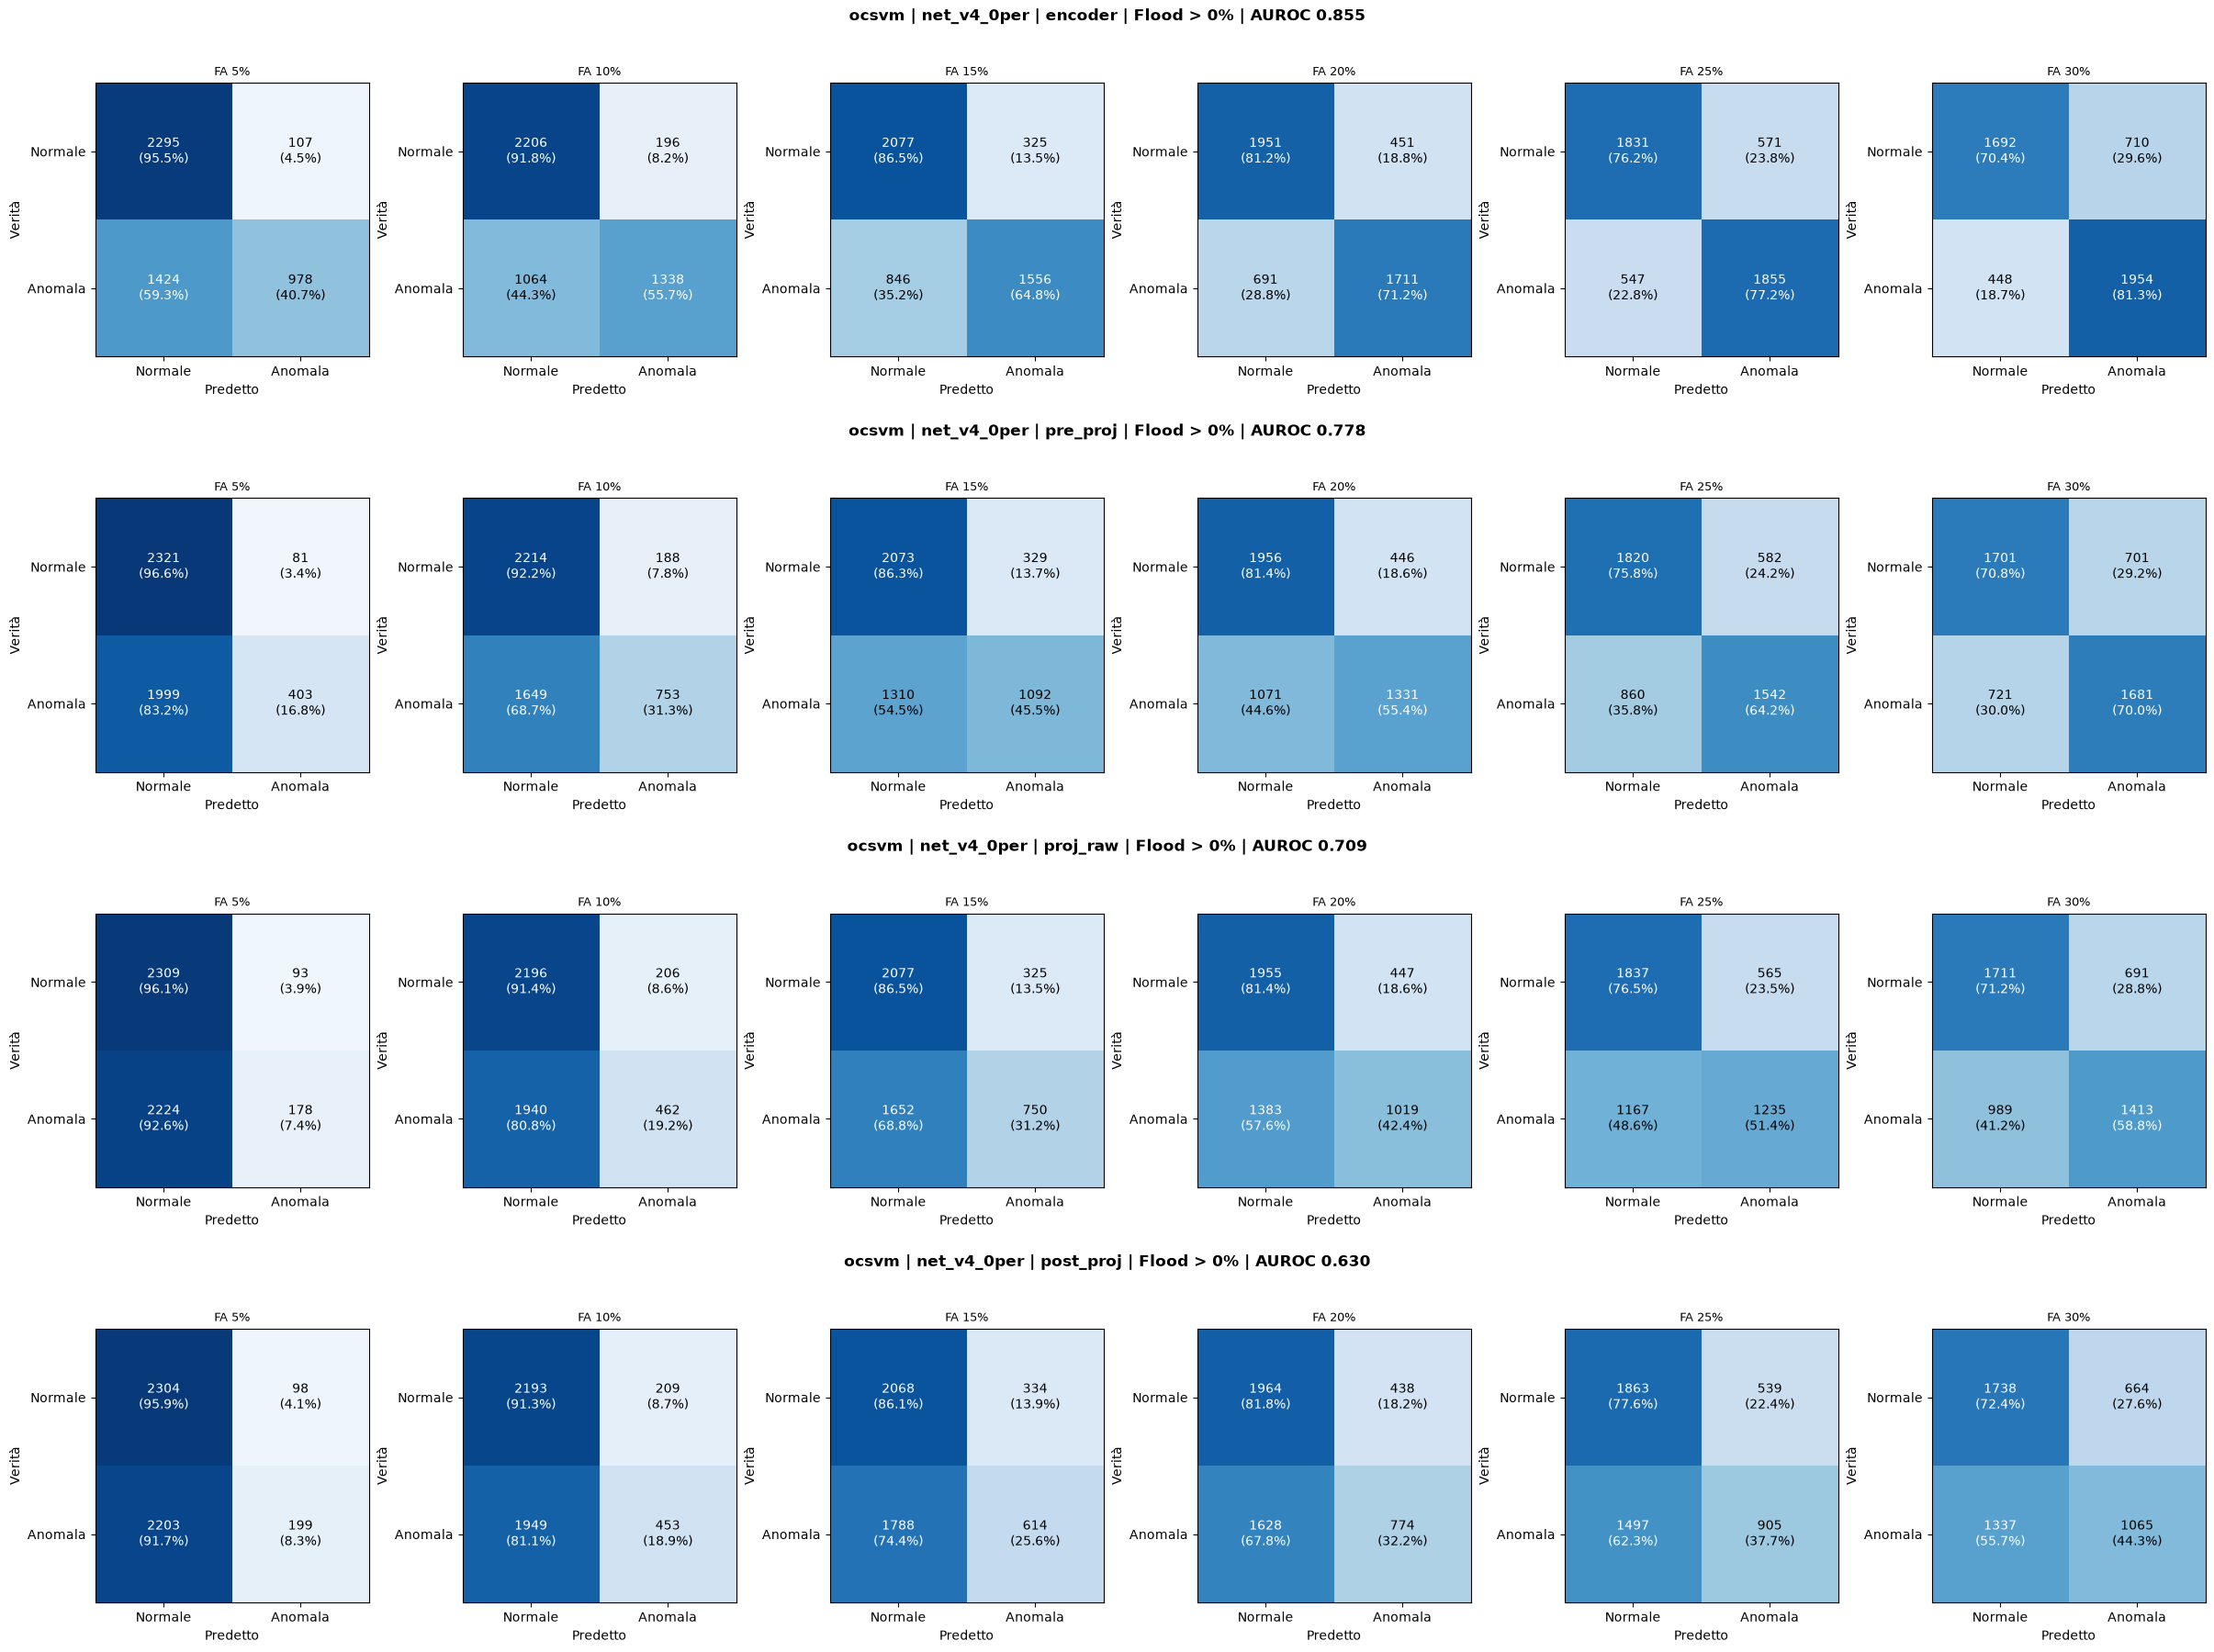

In [7]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [9]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                    
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}          
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC": auroc(md, n_val, a_val),                
    })

lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC": auroc(md, n_val, a_val),
})
print(f"Lw shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_net_v4_0per
job:           net_v4_0per | moco: net_v4 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.778 (ocsvm, whitening lw, 2048 componenti) 

forme: {'fit': (19893, 2048), 'thr': (2572, 2048), 'normal': (2402, 2048), 'anom': (2402, 2048)} 

Lw shrinkage: 0.014
           thr/fit  AUROC
k                        
32           1.103  0.664
64           1.072  0.680
128          1.054  0.716
256          1.031  0.735
512          1.013  0.755
768          1.019  0.763
1024         1.038  0.768
1536         1.099  0.772
2048         1.188  0.771
LW (2048)    1.174  0.771
